# Введение в регрессионный анализ

*Алла Тамбовцева*

## Практикум 2. Парная линейная регрессия. Метод наименьших квадратов

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

В файле `SBA_data.csv` сохранены данные о кредитах, одобренных администрацией по делам малого бизнеса США в 2020 году (фискальный год). Основные переменные:

* `BorrName`: название компании-заемщика;
* `BorrStreet`, `BorrCity`, `BorrState`: адрес, город, штат компании-заемщика;
* `BankName`: название банка, выдающего кредит;
* `BorrStreet`, `BorrCity`, `BorrState`: адрес, город, штат банка;
* `GrossApproval`: сумма кредита, одобренная банком;
* `SBA`: сумма кредита, гарантированная администрацией по делам малого бизнеса (в долларах);
* `InitialInterestRate`: начальная ставка по кредиту;
* `TermInMonths`: срок кредита;
* `LoanOk`: количество одобренных или выплаченных кредитов за предыдущие 10 лет (2010-2019 годы).

Источник оригинальных данных – [Kaggle](https://www.kaggle.com/datasets/thedevastator/sba-loan-guarantee-data-1990-1999), данные были отфильтрованы и преобразованы для задач данного семинара.

Загрузим данные из CSV-файла по ссылке:

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/allatambov/PyReg26/refs/heads/main/SBA_data.csv")
df.head()

,BorrName,BorrStreet,BorrCity,BorrState,BankName,BankStreet,BankCity,BankState,GrossApproval,SBA,ApprovalDate,ApprovalFiscalYear,InitialInterestRate,TermInMonths,LoanOk
0,Force Express LLC,7875 Newcomb DR,Parma,OH,The Huntington National Bank,17 S High St,COLUMBUS,OH,69700.0,34850.0,10-01-19,2020,5.35,84,2
1,"EASTERLIN PECAN CO., INC.",210 S DOOLY ST,MONTEZUMA,GA,Truist Bank d/b/a Branch Banking & Trust Co,214 N Tryon St,CHARLOTTE,NC,5000000.0,4500000.0,10-02-19,2020,5.50,12,3
2,CPS Corporation,21 BRIGHAM ST,WESTBOROUGH,MA,St. Mary's CU,46 Lizotte Dr,MARLBOROUGH,MA,52700.0,44795.0,10-04-19,2020,4.50,84,2
3,"KINTER TRUCKING, INC.",6968 State Route 7,Andover,OH,The Huntington National Bank,17 S High St,COLUMBUS,OH,25800.0,12900.0,10-07-19,2020,5.65,60,2
4,"Alamo Premium Distillery, Inc.",621 Chestnut,San Antonio,TX,The Bank of San Antonio,1900 NW Loop 410,SAN ANTONIO,TX,210300.0,157725.0,10-07-19,2020,6.00,84,2


## Постановка задачи и ключевые переменные

**Исследовательский вопрос.** Приводит ли увеличение количества одобренных или выплаченных кредитов за предыдущие годы (статусы *Commited* и *Paid in full*) к увеличению суммы кредита, гарантированной администрацией по делам малого бизнеса?

**Переменные.** Количество одобренных или выплаченных кредитов – столбец `LoanOk`, сумма кредита, гарантированная администрацией по делам малого бизнеса – столбец `SBA`. Для удобства интерпретации и сокращения разброса значений сумму кредита *необходимо перевести из долларов в тысячи долларов*.

### Задача 0

Добавьте в датафрейм `df` столбец `SBA2` со значениями суммы кредита, гарантированной администрацией по делам малого бизнеса, измеренной в тысячах долларов. 

**NB.** Во всех дальнейших заданиях используйте столбец `SBA2`, а не исходный `SBA`.

In [3]:
df["SBA2"] = df["SBA"] / 1000

### Задача 1

Определите, исходя из исследовательского вопроса, какая переменная является зависимой, а какая – независимой. Используя `pandas`, постройте диаграмму рассеивания для переменных, расположив независимую переменную по горизонтальной оси, а зависимую – по вертикальной.

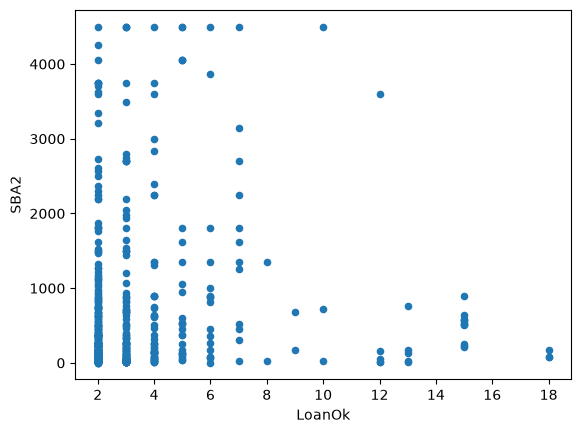

In [4]:
# зависимая (объясняемая): y = SBA2
# независимая (объясняющая): x = LoanOk

df.plot.scatter(x = "LoanOk", y = "SBA2");

### Задача 2

Ниже написан код, который создает ковариационную матрицу для столбцов `LoanOk` и `SBA2`:

In [5]:
cov_matrix = df[["LoanOk", "SBA2"]].cov()
cov_matrix

,LoanOk,SBA2
LoanOk,6.947816,235.368453
SBA2,235.368453,965566.155327


Ковариационная матрица выше – это маленький датафрейм, таблица из двух строк и двух столбцов. Для выбора элементов таблицы по индексам строки и столбца в `pandas` существует метод `.iloc` (от *index location*). Например, выбор элемента в первой строке (индекс 0) в первом столбце (индекс 0) будет выглядеть так:

    cov_matrix.iloc[0, 0]

Используя `cov_matrix`, сохраните в `var_x` дисперсию независимой переменной, в `var_y` – дисперсию зависимой переменной, в `cov_xy` – ковариацию независимой и зависимой переменной.

In [6]:
var_x = cov_matrix.iloc[0, 0]
var_y = cov_matrix.iloc[1, 1]
cov_xy = cov_matrix.iloc[0, 1]

### Задача 3

Используя результаты задачи 2, вычислите коэффициент Пирсона между независимой и зависимой переменной. Для извлечения квадратного корня можете использовать функцию `sqrt()` из `numpy`.

In [7]:
cov_xy / (np.sqrt(var_x) * np.sqrt(var_y))

np.float64(0.0908726293842825)

In [9]:
# если бы считали не по формулам, могли бы применить 
# метод .corr() по аналогии с .cov() в задаче 2

df[["LoanOk", "SBA2"]].corr()

,LoanOk,SBA2
LoanOk,1.000000,0.090873
SBA2,0.090873,1.000000


> Получилась корреляционная матрица. Коэффициент корреляции переменной самой с собой равен 1, на побочной диагонали – коэффициенты корреляции К.Пирсона. Если нам потребудется коэффициент отдельно, заберем элемент через `.iloc`.

In [10]:
df[["LoanOk", "SBA2"]].corr().iloc[0, 1]

np.float64(0.09087262938428253)

### Задача 4

Используя результаты задачи 2, вычислите оценки коэффициентов $\hat{b}_1$ и $\hat{b}_0$. Сохраните их переменные `b1` и `b0`. Запишите уравнение модели и проинтерпретируйте полученные результаты.

In [8]:
b1 = cov_xy / var_x
b0 = df["SBA2"].mean() - b1 * df["LoanOk"].mean()
print(b0)
print(b1)

486.4706575362528
33.876612115097615


> Уравнение модели: $\hat{y}_i = \hat{b}_0 + \hat{b}_1 x_i$, оно же $\widehat{SBA2}_i = 486.47 + 33.88 \times \text{LoanOk}_i$. Согласно модели, компания с нулевым числом закрытых кредитов может ожидать, в среднем, гарантированную сумму кредита равную 486.47 тысячам долларов. При увеличении числа закрытых кредитов на 1, гарантированная сумма кредита, в среднем, увеличивается на 33.88 тысяч долларов. То есть, если сравнивать компании между собой, у тех, у которых в кредитной истории закрытых кредитов на один больше, сумма гарантированного кредита, в среднем, на 33.88 тысяч долларов выше.

### Задача 5

Получите оценки коэффициентов $\hat{b}_1$ и $\hat{b}_0$ с помощью функции `polyfit()` из `numpy`. Сравните результаты с ответами в задаче 4.

In [11]:
# на первом месте – независимая переменная,
# на втором месте – зависимая переменная,
# на выходе получаем массив, сначала b1, потом b0

b1, b0 = np.polyfit(df["LoanOk"], df["SBA2"], deg=1)
print(b0)
print(b1)

486.4706575362492
33.87661211509839


> Результаты те же, функция `polyfit()` c `deg=1` вычисляет оценки коэффициентов линейной модели.

### Задача 6

Используя значения `b0` и `b1`, вычислите предсказанные (прогнозные) значения зависимой переменной. Добавьте их в датафрейм `df` – добавьте новый столбец `yhat`. 

In [12]:
# подставляем в уравнение независимую переменную
df["yhat"] = b0 + b1 * df["LoanOk"]

### Задача 7

Ниже написан код, который добавляет на диаграмму рассеивания регрессионную прямую в предположении, что в переменной `x` сохранен столбец со значениями независимой переменной, в `y` – столбец со значениями звисимой переменной, в `ypred` – столбец с предсказанными значениями зависимой переменной. 

* Допишите код для создания переменных `y` и `ypred`.
* Определите (примерно, на глаз) значение остатка для наблюдения $x = 12$, $y = 3600$. Проинтерпретируйте это значение.
* Определите, используя результаты задачи 4, точное значение остатка для этого наблюдения.

In [13]:
# выбираем нужные столбцы
x = df["LoanOk"]
y = df["SBA2"]
ypred = df["yhat"]

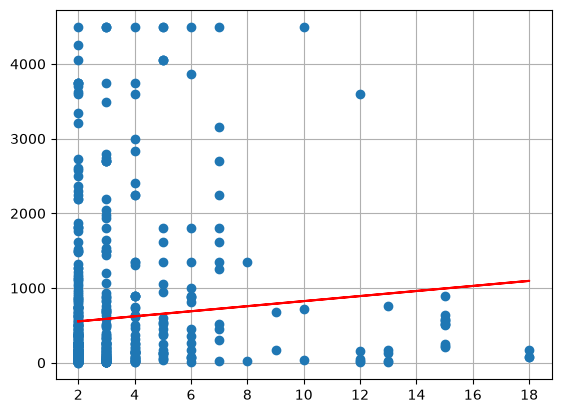

In [14]:
fig, ax = plt.subplots()
ax.scatter(x, y);
ax.plot(x, ypred, color = "red");
ax.grid();
ax.set_axisbelow(True);

> Остаток на глаз: для точки $x=12$ координата по $y$ равна 3600, а предсказанное значение $\hat{y}$ (на красной регрессионной прямой) равно примерно 900. Значит, остаток $\hat{\varepsilon}_i = y_i - \hat{y}_i = 3600 - 900 = 2700$. Для более точного значения подставим $x$ в уравнение.

In [15]:
y_real = 3600
y_predicted = b0 + b1 * 12
epsilon = y_real - y_predicted
print(epsilon)

2707.0099970825704


### Задача 8

Добавьте в датафрейм `df` столбец `resid` со значениями остатков модели для всех наблюдений. Вычислите RSS – сумму квадратов остатков.

In [16]:
# добавляем разность столбцов y - y^
# возводим столбец в квадрат и считаем сумму

df["resid"] = df["SBA2"] - df["yhat"]
RSS = (df["resid"] ** 2).sum()
print(RSS)

583173935.7595173


> Значение получилось огромным (мы и по графику видели, что модель не очень подходит к данным), но это минимальное значение RSS из возможных, поскольку минимизация суммы квадратов остатков гарантируется методом наименьших квадратов, который используется для вычисления оценок коэффициентов модели. В данном случае большое значение RSS получается не только из-за слабой линейной связи между переменными, но и из-за большого диапазона значений зависимой переменной. 

**Важно.** Сумма самих остатков без возведения в квадрат должна равняться 0, но из-за накопленной ошибки при работе
с дробными числами в Python получается не «чистый» 0, а очень маленькое число:

In [17]:
# на разных компьютерах и версиях numpy
# могут быть разные результаты, здесь это
# 6.11 * 10  в степени (-10)

print(df["resid"].sum())

6.111804395914078e-10
